# UCS and GBFS on the US Patent Citation Network

This notebook compares Uniform Cost Search and Greedy Best-First Search on the Stanford SNAP `cit-Patents` network. It shows the archived measurements and uses the same Python package as the command-line benchmark for fresh experiments.

Install the repository with `python -m pip install -r requirements-notebook.txt`. Launch Jupyter from the repository root. The full benchmark loads the official edge list and may require several GB of available RAM. For offline use, set `PATENT_DATASET` to the absolute path of a local SNAP text or gzip file, or place it in the repository's `data/` cache.

## 1. Directed routes and search priorities

A citation $A \to B$ means patent A cites patent B. Every retained citation has unit cost. The graph keeps unique non-self edges with both patent IDs at least 5,000,000, in file order.

UCS selects the route with minimum $g(n)$, its accumulated cost. With finite nonnegative edge costs it returns a minimum-cost route. GBFS selects by $h(n)=\lvert\mathrm{ID}(n)-\mathrm{ID}(t)\rvert$ for goal $t$. This gap orders candidates. It can overestimate hop distance and can lead to a longer route. Both searches resolve equal priorities by the smaller patent ID and test the goal on selection. The original list frontier and per-entry route are retained.

UCS appends improved routes and skips stale selections. GBFS marks states on insertion. Both terminate on finite graphs with duplicate detection. The counter includes selected goals and excludes stale entries.

In [1]:
import os
from pathlib import Path
from uuid import uuid4

import pandas as pd
from IPython.display import Image, display

from patent_search.examples import TINY_GRAPH, WEIGHTED_GRAPH, weighted_step
from patent_search.experiments import run_experiment
from patent_search.search import greedy_search, is_valid_path, ucs_search

here = Path.cwd()
root = next((p for p in (here, *here.parents) if (p / "results/recorded/provenance.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Start Jupyter from the repository root or notebooks directory")
recorded = root / "results/recorded"


## 2. Unit-cost and weighted examples

The unit-cost toy graph has two routes of depth three. The weighted graph shows that a route with fewer hops may cost more. The measured patent dataset uses unit costs throughout.

In [2]:
ucs = ucs_search(TINY_GRAPH, 1, 6)
gbfs = greedy_search(TINY_GRAPH, 1, 6)
assert ucs == ([1, 2, 4, 6], 6, 2)
assert gbfs == ([1, 3, 5, 6], 4, 3)
print("Unit-cost search returns (route, selected states, maximum frontier)")
print("UCS ", ucs)
print("GBFS", gbfs)

rows = []
for name, search, options in (
    ("UCS", ucs_search, {"edge_cost": weighted_step}),
    ("GBFS", greedy_search, {}),
):
    route, selected, maximum = search(WEIGHTED_GRAPH, 1, 10, **options)
    assert is_valid_path(WEIGHTED_GRAPH, route, 1, 10)
    cost = sum(weighted_step(a, b) for a, b in zip(route, route[1:]))
    rows.append({"algorithm": name, "route": route, "cost": cost,
                 "selected states": selected, "maximum frontier": maximum})
assert [row["cost"] for row in rows] == [4, 20]
display(pd.DataFrame(rows))


,algorithm,route,cost,selected states,maximum frontier
0,UCS,"[1, 2, 3, 4, 10]",4,5,2
1,GBFS,"[1, 8, 10]",20,3,2


## 3. Archived academic run

These tables and figures come from the saved execution accompanying the academic report. The snapshot preserves its CSV values. Both algorithms solved all 50 main pairs with valid minimum-hop routes. GBFS matched UCS cost on all 50, selected fewer states on 47 and tied on three. The mean selected-state count was 293.0 for UCS and 215.1 for GBFS.

The depth follow-up found 20 pairs each at depths 2, 4, and 6 and three at depth 8. It found none at depths 10 and 12 under the sampling budget. GBFS selected more states on average at depth 2. The first main pair had 32 UCS selections and 28 GBFS selections. Its route is identical under both algorithms.

The original protocol warms up each search once, then records the median of five untraced runs for that pair. A separate search measures peak traced Python allocations after graph construction. These resource measurements can vary on re-execution.

,Measure,UCS,GBFS
0,Success rate (%),100.000,100.000
1,Valid paths among found paths (%),100.000,100.000
2,Average path cost,8.040,8.040
3,Average solution depth,8.040,8.040
4,Average nodes expanded,293.000,215.100
5,Average max frontier size,97.400,30.600
6,Average time per pair (ms),1.892,0.567
7,Average peak traced memory (KiB),37.700,16.300
8,Total time for all pairs (s),0.901,0.284


,exact depth,pairs,source attempts,UCS avg cost,GBFS avg cost,GBFS optimal (%),UCS avg nodes,GBFS avg nodes
0,2,20,28,2.0,2.0,100.0,10.4,11.6
1,4,20,119,4.0,4.0,100.0,68.0,58.3
2,6,20,591,6.0,6.0,100.0,170.8,142.8
3,8,3,2000,8.0,8.0,100.0,377.0,314.3
4,10,0,2000,NaN,NaN,NaN,NaN,NaN
5,12,0,2000,NaN,NaN,NaN,NaN,NaN


,algorithm,selected states,states outside final route,heuristic increases,goal selection step
0,UCS,32,23,22,32
1,GBFS,28,19,15,28


,pair,source,goal,path_cost_ucs,path_cost_gbfs,nodes_expanded_ucs,nodes_expanded_gbfs,max_frontier_ucs,max_frontier_gbfs
0,1,5973621,5020969,8,8,32,28,9,6
1,2,5877814,5051467,8,8,76,76,21,11
2,3,5913866,5050016,8,8,168,96,71,19
3,4,5873095,5020969,8,8,638,262,229,27
4,5,5945660,5080554,8,8,295,292,119,31
5,6,5867665,5033352,8,8,567,533,164,21
6,7,5815156,5008884,8,8,377,99,173,34
7,8,6006098,5043981,8,8,458,384,167,25
8,9,5966615,5053351,8,8,330,162,88,15
9,10,5845212,5159541,8,8,168,161,50,15


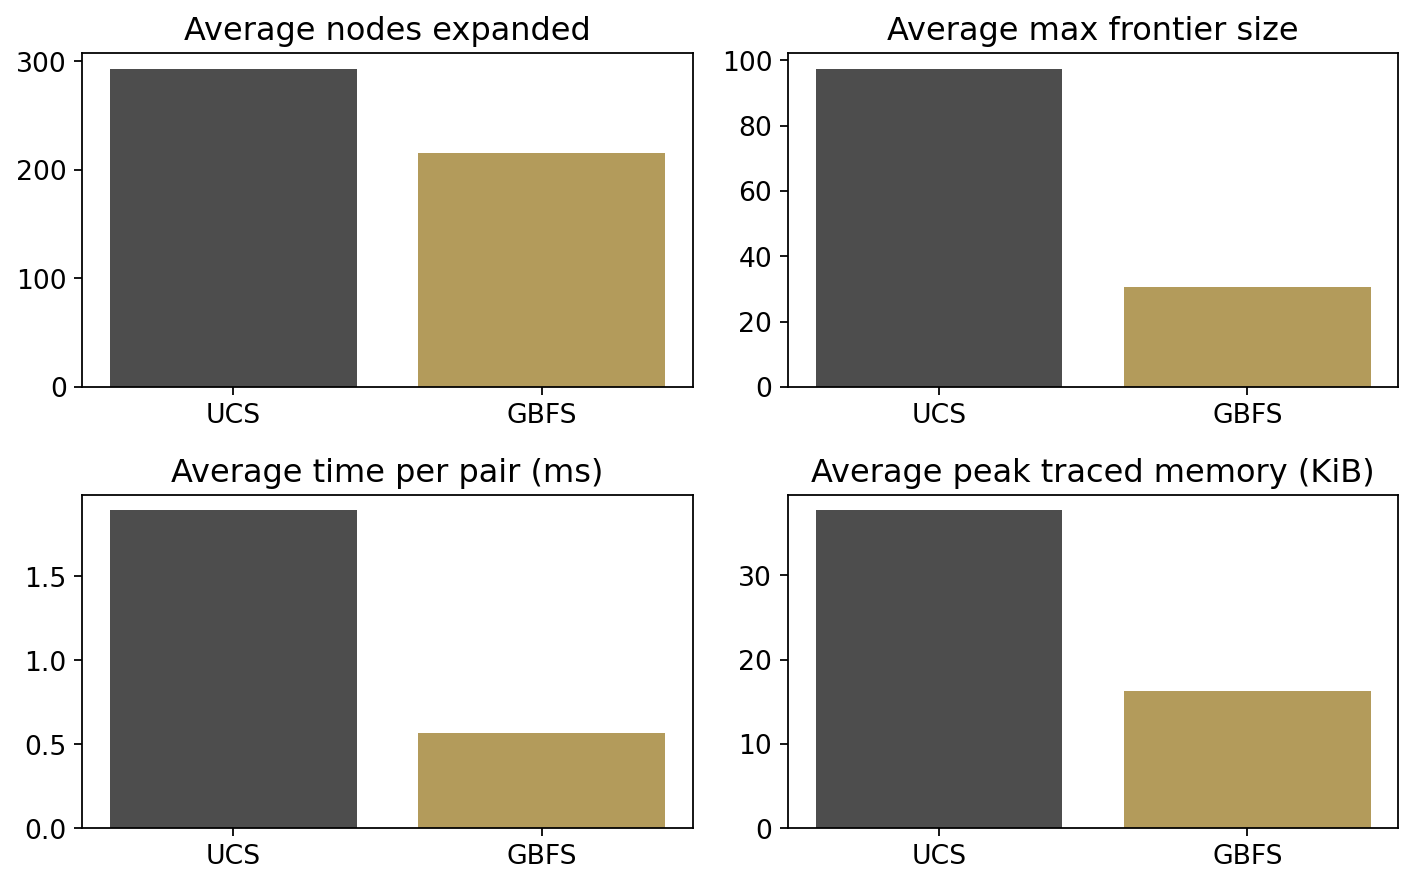

In [3]:
for filename in ("comparison.csv", "depth_sensitivity.csv", "expansion_analysis.csv"):
    print("Archived", filename)
    display(pd.read_csv(recorded / filename))

columns = ["pair", "source", "goal", "path_cost_ucs", "path_cost_gbfs",
           "nodes_expanded_ucs", "nodes_expanded_gbfs", "max_frontier_ucs", "max_frontier_gbfs"]
pairs = pd.read_csv(recorded / "pair_optimality.csv", usecols=columns)
with pd.option_context("display.max_rows", 50):
    display(pairs[columns])
display(Image(filename=str(recorded / "figures" / "performance.png")))


## 4. Fresh reproduction

The runner loads the same dataset and samples 50 reachable ordered pairs with BFS shortest distances 8–14 and seed 7. The separate exact-depth experiment requests 20 pairs per depth with seed 11 and up to 2,000 source draws per depth. The runner validates every main route, checks the UCS costs against independent BFS distances, and exports fresh CSVs and figures in a new run directory.

In [ ]:
dataset_path = os.environ.get("PATENT_DATASET")
dataset = Path(dataset_path).expanduser() if dataset_path else None
run_directory = root / "runs" / f"notebook-{uuid4().hex[:12]}"
fresh = run_experiment(run_directory, dataset=dataset, cache=root / "data")
print("Fresh run completed")
display(fresh["comparison"])
display(fresh["depth_sensitivity"])
display(fresh["expansion_analysis"])


## 5. Compare deterministic outputs

The verification script compares graph counts, pair identities, routes, costs, path validity, selected-state and frontier counts, depth samples, and expansion orders. Timing and traced allocation are kept with the run that produced them.

In [ ]:
from patent_search.verification import verify

checked = verify(run_directory, recorded)
assert checked["status"] == "pass"
display(pd.DataFrame.from_dict(checked["tables"], orient="index"))
display(Image(filename=str(run_directory / "figures" / "expansion_order.png")))


## 6. Limitations and future work

The main benchmark concentrates on depth-eight queries and conditions on reachable pairs in one filtered graph. The depth-eight follow-up contains three pairs, and the deepest requested samples yielded no pairs under the source budget. The numerical heuristic is graph-specific. Timing and memory figures describe their recorded environments.

A separate benchmark could test depth-balanced samples, different thresholds, heap frontiers, parent pointers, or A* with a justified heuristic. BFS serves as a sampling and distance-validation tool in this project.

[Methodology](../docs/methodology.md) · [Reproducibility](../docs/reproducibility.md) · [References](../docs/references.md) · [SNAP dataset](https://snap.stanford.edu/data/cit-Patents.html)